# Ordenación por inserción (insertion sort)

Toma cada elemento y lo inserta en su lugar dentro de la parte ya ordenada, desplazando los mayores a la derecha. Cuesta $O(n^2)$ en el peor caso, pero $O(n)$ si la lista está casi ordenada, y es estable.

## 1. Inserción

Ordenar una lista de menor a mayor por inserción, en el sitio.

In [1]:
import random

def insertion_sort(l):
    for i in range(1, len(l)):
        actual, j = l[i], i - 1
        while j >= 0 and l[j] > actual:
            l[j + 1] = l[j]
            j -= 1
        l[j + 1] = actual
    return l

for _ in range(200):
    datos = random.choices(range(100), k=random.randint(0, 30))
    assert insertion_sort(datos[:]) == sorted(datos)
print(insertion_sort([12, 11, 13, 5, 6]))

[5, 6, 11, 12, 13]


## 2. Inserción con clave

Ordenar una lista de tuplas `(nombre, edad)` por edad conservando el orden original entre empates (estabilidad).

In [2]:
def insertion_sort_clave(l, clave):
    for i in range(1, len(l)):
        actual, j = l[i], i - 1
        # > estricto mantiene estabilidad
        while j >= 0 and clave(l[j]) > clave(actual):
            l[j + 1] = l[j]
            j -= 1
        l[j + 1] = actual
    return l

personas = [("Ana", 30), ("Luis", 25), ("Eva", 30), ("Pau", 25)]
print(insertion_sort_clave(personas, lambda p: p[1]))

[('Luis', 25), ('Pau', 25), ('Ana', 30), ('Eva', 30)]


## 3. Mejor y peor caso

Contar comparaciones y desplazamientos. Comprobar que los desplazamientos son exactamente las inversiones de la lista y dibujar las comparaciones en función de $n$ para una lista ordenada ($n - 1$, el mejor caso), casi ordenada (5 parejas vecinas cambiadas), aleatoria (unas $\frac{n^2}{4}$) e inversa ($\frac{n(n-1)}{2}$, el peor caso).

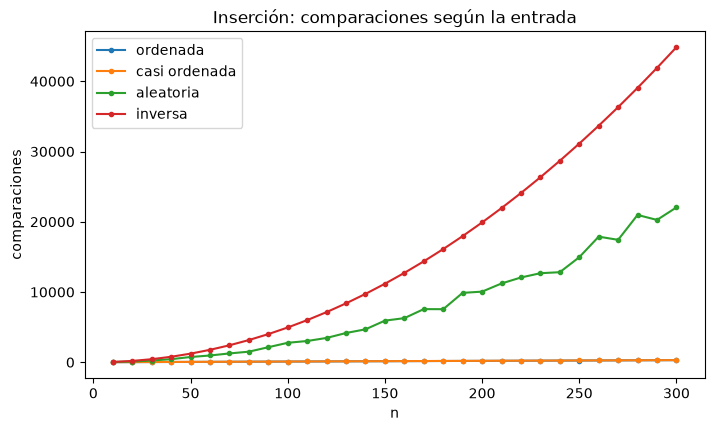

In [3]:
import matplotlib.pyplot as plt

def insertion_sort_contando(lista):
    l, comparaciones, desplazamientos = lista[:], 0, 0
    for i in range(1, len(l)):
        actual, j = l[i], i - 1
        while j >= 0:
            comparaciones += 1
            if l[j] <= actual:
                break
            l[j + 1] = l[j]
            desplazamientos += 1
            j -= 1
        l[j + 1] = actual
    return l, comparaciones, desplazamientos

def inversiones(lista):
    return sum(lista[i] > lista[j] for i in range(len(lista)) for j in range(i + 1, len(lista)))

def casi_ordenada(n):
    l = list(range(n))
    for i in random.sample(range(n - 1), 5):
        l[i], l[i + 1] = l[i + 1], l[i]
    return l

random.seed(3)
for _ in range(200):
    datos = random.choices(range(50), k=random.randint(0, 30))
    l, _, desplazamientos = insertion_sort_contando(datos)
    assert l == sorted(datos) and desplazamientos == inversiones(datos)

casos = {
    "ordenada": lambda n: list(range(n)),
    "casi ordenada": casi_ordenada,
    "aleatoria": lambda n: random.sample(range(n), n),
    "inversa": lambda n: list(range(n, 0, -1)),
}
tamanos = range(10, 301, 10)
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, genera in casos.items():
    comparaciones = [insertion_sort_contando(genera(n))[1] for n in tamanos]
    ax.plot(tamanos, comparaciones, marker=".", label=nombre)
assert all(insertion_sort_contando(list(range(n)))[1] == n - 1 for n in tamanos)
assert all(insertion_sort_contando(list(range(n, 0, -1)))[1] == n * (n - 1) // 2 for n in tamanos)
ax.set(xlabel="n", ylabel="comparaciones", title="Inserción: comparaciones según la entrada")
ax.legend()
plt.show()

## 4. Inserción binaria

Buscar la posición de inserción con búsqueda binaria, a la derecha de los iguales para que siga siendo estable. Las comparaciones bajan a $O(n \log n)$, pero los desplazamientos siguen siendo $O(n^2)$. Compararla con la inserción lineal y probar `bisect.insort`, que inserta un elemento en una lista ordenada de la misma forma.

In [4]:
import bisect

def primero(registro):
    return registro[0]

def insercion_binaria(lista, clave=lambda x: x):
    l, comparaciones = lista[:], 0
    for i in range(1, len(l)):
        actual, izq, der = l[i], 0, i
        while izq < der:
            medio = (izq + der) // 2
            comparaciones += 1
            # con iguales sigue hacia la derecha: estable
            if clave(actual) < clave(l[medio]):
                der = medio
            else:
                izq = medio + 1
        l[izq + 1:i + 1] = l[izq:i]
        l[izq] = actual
    return l, comparaciones

random.seed(4)
for _ in range(300):
    datos = [(random.randint(0, 5), i) for i in range(random.randint(0, 25))]
    assert insercion_binaria(datos, primero)[0] == sorted(datos, key=primero)

datos = random.sample(range(1000), 1000)
print("Comparaciones con inserción lineal: ", insertion_sort_contando(datos)[1])
print("Comparaciones con inserción binaria:", insercion_binaria(datos)[1])
print("Elementos desplazados en las dos:   ", inversiones(datos))

ordenada = []
for x in [5, 1, 4, 2, 3, 4]:
    bisect.insort(ordenada, x)
print(ordenada)

Comparaciones con inserción lineal:  248142
Comparaciones con inserción binaria: 8587
Elementos desplazados en las dos:    247149
[1, 2, 3, 4, 4, 5]
